In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
# import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib.colors import LogNorm
import fastplotlib as fpl
import tifffile
from skophys.viz_helpers import spatial_to_rgba
from skophys.datasets import ARProcess, ARProcessMovie
from tifffile.tifffile import imwrite
from scipy.optimize import curve_fit
import pickle

from caiman.paths import caiman_datadir

%matplotlib inline

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/pygfx/utils/_dirs.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [2]:
fig_label = "test"

# fig_label += "_noncentered"
# use_centering = 0 # no centering
# fig_label += "_precentered"
# use_centering = 1 # only center whitening matrix
# fig_label += "_fullcentered"
# use_centering = 2 # center both whitening matrix and data
fig_label += "_filtercentered"
use_centering = 3 # center both whitening matrix and data

n_time_windows = 10

analysis_type = 0 # similarity matching
# analysis_type = 1 # covariance matching
# analysis_type = 2 # hybrid matching

# fig_label += "_fitbias"
# fit_bias = True
fig_label += "_nofitbias"
fit_bias = False

fig_label += "_whiten"
use_whitening = True
# fig_label += "_nonwhiten"
# use_whitening = False

fig_label += "_truncated"
truncate_spectrum = True
# fig_label += "_nontruncated"
# truncate_spectrum = False

# denoise_diagonal = True
denoise_diagonal = False

use_eco_init = True
# use_eco_init = False

n_lags = 0
# n_lags = 2
fig_label += f"_{n_lags}lag"


lag_time = 1

In [3]:
# simulation = True
simulation = False

In [4]:

# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/dendrites_rect.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/sue2p.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/1p.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/vaz_crop_2.tif"

# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/vaz_crop_1.tif"

# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/885D5_MC_rect-0_n-clusters-10.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/885D5_MC_rect-3_n-clusters-19.tif"
# path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/M19D5_MC_rect-1_n-clusters-19.tif"

# path = "/Users/rshang/Work/fermipy/make_movie_array/raw_gamma_ray_movie.pkl"
path = "/Users/rshang/Work/fermipy/make_movie_array/smooth_gamma_ray_movie.pkl"

In [5]:
def remove_duplicate_rows(matrix):
    matrix = np.array(matrix)
    unique_matrix = np.unique(matrix, axis=1)
    return unique_matrix

In [6]:
if simulation:

    # obs_noise_level = 0.0
    obs_noise_level = 0.1
    # obs_noise_level = 0.3
    # obs_noise_level = 0.6
    # obs_noise_level = 0.9
    # obs_noise_level = 1.2
    ar_noise_sigma = 0.01
    ar_bias = 0.0
    # ar_bias = 5.0
    # bkg_bias = 0.0
    # bkg_bias = 2.0
    # bkg_bias = 4.0
    bkg_bias = 8.0
    # fp = 0.1
    fp = 0.01
    # fp = 0.005
    # rise_constant = 5.
    rise_constant = 2.
    # decay_constant = 0.98
    # decay_constant = 0.95
    # decay_constant = 0.80
    decay_constant = 0.5
    
    random_seed = 9
    np.random.seed(random_seed)

    fig_label += f"_noise{obs_noise_level}"

    sim_time_steps = 1000

    dims = 30, 30
    n_sources = 50
    source_size = 1
    # decay_constant = 0.98
    decay_constant = 0.8

    # dims = 15, 15
    # n_sources = 10
    # source_size = 2
    # decay_constant = 0.6
    
    locs = (np.random.rand(100, 2) * dims[0]).clip(0).astype(int)
    locs = remove_duplicate_rows(locs)
    
    # dims = 20, 20
    # source_size = 2
    # n_sources = 2
    # locs = (np.random.rand(2, 2) * dims[0]).clip(0).astype(int)
    # # locs[0,0] = 6
    # # locs[0,1] = 10
    # # locs[1,0] = 14
    # # locs[1,1] = 10
    # locs[0,0] = 9
    # locs[0,1] = 10
    # locs[1,0] = 10
    # locs[1,1] = 10

if simulation:
    plt.imshow(np.zeros(dims))
    plt.scatter(locs[:, 0], locs[:, 1], c="r")
    plt.show()

In [7]:
if simulation:
    burn_steps = 200
    S = ARProcessMovie(
        n_timepoints=sim_time_steps+burn_steps,
        n_components=n_sources,
        ar_noise_sigma=ar_noise_sigma,
        ar_bias=ar_bias,
        obs_noise_sigma=0.0,
        movie_dims=dims,
        component_size=source_size,
        component_locs=locs,
        rise_constant = rise_constant,
        decay_constant = decay_constant,
        # baselines=[1, 1],
        firing_probability=fp,
        random_seed=random_seed,
    )
    
    B = ARProcessMovie(
        n_timepoints=sim_time_steps+burn_steps,
        n_components=1,
        ar_noise_sigma=0.0,
        ar_bias=bkg_bias,
        obs_noise_sigma=0.0,
        movie_dims=dims,
        component_size=max(int(dims[0]/5),1),
        component_locs=locs,
        rise_constant = rise_constant,
        decay_constant = decay_constant,
        firing_probability=0.,
        random_seed=random_seed,
    )
    
    sns.heatmap(S.kernel, cmap="viridis")
    
    fname = os.path.join(caiman_datadir(), 'example_movies', '/Users/rshang/Work/caiman/mesmerize-core/exp_data/ToySim2D.tif')
    imwrite(fname, S.movie)

In [8]:
if simulation:
    traces = S.traces[:,burn_steps:]
    traces_obs = S.traces_obs[:,burn_steps:]
    
    # fig, ax = plt.subplots(figsize=(6, 3))
    # for src in range(0,len(traces)):
    #     ax.plot(traces[src])
    # ax.axhline(y=0, color='r', linestyle='--')
    # plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_trace_{fig_label}.png')
    # plt.show()
    
    if len(traces)>1:
        fig, ax = plt.subplots(len(traces), 1, figsize=(10, len(traces)))
        for src in range(0,len(traces)):
            ax[src].plot(traces[src])
        plt.tight_layout()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_trace_{fig_label}.png')
        plt.show()

In [9]:
if simulation:
    source_footprints = S.source_footprints
    print (f"source_footprints.shape = {source_footprints.shape}")

In [10]:
if simulation:
    S_movie = S.movie[burn_steps:,:,:]
    B_movie = B.movie[burn_steps:,:,:]
    
    N_movie = obs_noise_level * np.random.randn(S_movie.shape[0], S_movie.shape[1], S_movie.shape[2])
    
    # mid_time_point = int(S_movie.shape[0]/2)
    # N_movie_1 = 0.2 * obs_noise_level * np.random.randn(mid_time_point, S_movie.shape[1], S_movie.shape[2])
    # N_movie_2 = 2. * obs_noise_level * np.random.randn(mid_time_point, S_movie.shape[1], S_movie.shape[2])
    # N_movie = np.vstack((N_movie_1, N_movie_2))
    
    N_movie += obs_noise_level * B_movie * np.random.randn(S_movie.shape[0], S_movie.shape[1], S_movie.shape[2])
    
    # movie = S_movie + N_movie
    movie = S_movie + B_movie + N_movie
    
    # Convert the data type to float32
    S_movie = S_movie.astype(np.float32)
    B_movie = B_movie.astype(np.float32)
    movie = movie.astype(np.float32)
    # movie = movie.astype(np.float32)[:, ::2, ::2]
    print (movie.shape)

In [11]:
if simulation:
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    im = plt.imshow(S_movie.mean(axis=0))
    truth_levels = [0.60]
    for src in range(0,n_sources):
        plt.contour(source_footprints[src], levels=truth_levels, colors='r')
    cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=1.0)
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_image_truth_{fig_label}.png')

    plt.imshow(B_movie.mean(axis=0))
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/bakcground_image_{fig_label}.png')

In [12]:
if not simulation:

    if "pkl" not in path:

        movie = tifffile.imread(path)[:]
        
        target_pix_dim = 15
        target_time_dim = 2000
        image_center_pix_x = int(movie.shape[1]/2)
        image_center_pix_y = int(movie.shape[2]/2)

        movie = movie[:target_time_dim, ::2, ::2]
        # movie = movie[:target_time_dim, image_center_pix_x-target_pix_dim:image_center_pix_x+target_pix_dim, image_center_pix_y-target_pix_dim:image_center_pix_y+target_pix_dim]
    
        # Convert the data type to float32
        movie = movie.astype(np.float32)

        B_movie = movie.mean(axis=0, keepdims=True)
        N_movie = np.sqrt(B_movie) * np.random.randn(movie.shape[0], movie.shape[1], movie.shape[2])

    else:
        print(f"Loading histogram from pickle file: {path}")
        
        with open(path, 'rb') as f:
            data_loaded = pickle.load(f)
            n_energy_bins = data_loaded['n_energy_bins']
            
            movie = data_loaded['histogram']
            for t in range (0,movie.shape[0]):
                movie[t,:,:] = movie[t,:,:].T

            N_movie = data_loaded['noise_histogram']
            for t in range (0,N_movie.shape[0]):
                N_movie[t,:,:] = N_movie[t,:,:].T
                
            # edges = data_loaded['edges']

        n_time_windows = n_energy_bins

    
    print (movie.shape)
    print (N_movie.shape)

Loading histogram from pickle file: /Users/rshang/Work/fermipy/make_movie_array/smooth_gamma_ray_movie.pkl
(120, 80, 80)
(120, 80, 80)


In [13]:
import imageio
# import imageio.v3 as iio

def convert_matrix_to_gif(movie_matrix, output_filename, fps=10):
    """
    Converts a 3D NumPy array with shape (T, X, Y) into a GIF file.
    """
    # Ensure the data type is uint8, which is expected by imageio for GIFs.
    # If the data is in a different range (e.g., 0.0 to 1.0), it should be
    # scaled to 0-255 before being converted to uint8.
    if movie_matrix.dtype != np.uint8:
        print("Warning: Input data is not of type uint8.")
        print("Scaling data to the 0-255 range and converting to uint8.")
        
        # Normalize to 0-1 range first
        matrix_min = movie_matrix.min()
        matrix_max = movie_matrix.max()
        if matrix_max > matrix_min:
            movie_matrix = (movie_matrix - matrix_min) / (matrix_max - matrix_min)
        else:
            # Handle the case where all values are the same
            movie_matrix = np.zeros_like(movie_matrix)
            
        # Scale to 0-255 and convert type
        movie_matrix = (movie_matrix * 255).astype(np.uint8)

    print (f"movie_matrix.shape = {movie_matrix.shape}")
    # The imageio.mimsave function takes a list of frames (2D arrays)
    # and saves them as a single animated file.
    try:
        print(f"Saving GIF to {output_filename}...")
        # bytes_image = iio.imwrite("<bytes>", movie_matrix, extension=".gif")
        imageio.mimsave(output_filename, movie_matrix, fps=fps, palettesize=1000)
        # Provide the absolute path for clarity on where the file is saved.
        print(f"Successfully saved GIF to: {os.path.abspath(output_filename)}")
    except Exception as e:
        print(f"An error occurred while saving the GIF: {e}")

convert_matrix_to_gif(movie, f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_movie_{fig_label}.gif')

Scaling data to the 0-255 range and converting to uint8.
movie_matrix.shape = (120, 80, 80)
Saving GIF to /Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_movie_test_filtercentered_nofitbias_whiten_truncated_0lag.gif...
Successfully saved GIF to: /Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_movie_test_filtercentered_nofitbias_whiten_truncated_0lag.gif


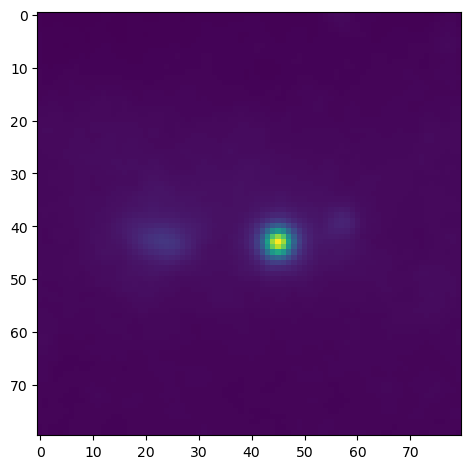

In [14]:
im = plt.imshow(movie.mean(axis=0))
if simulation:
    truth_levels = [0.60]
    for src in range(0,n_sources):
        plt.contour(source_footprints[src], levels=truth_levels, colors='r')
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/data_image_{fig_label}.png')

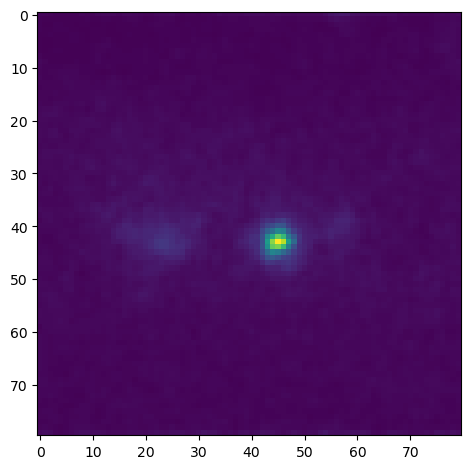

In [15]:
plt.imshow(N_movie.var(axis=0))
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/noise_image_{fig_label}.png')

In [16]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie)
Xn = vectorizer.fit_transform(N_movie)

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [17]:
n_pixels = X.shape[0]
n_time_steps = X.shape[1]

print (f"n_pixels = {n_pixels}")
print (f"n_time_steps = {n_time_steps}")

n_pixels = 6400
n_time_steps = 120


In [18]:
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    eigenvalues, eigenvectors = np.linalg.eigh(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

def covariance_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    T = X.shape[1]
    COV = X @ X.T / float(T)
    
    return COV

def similarity_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples
    
    N = X.shape[0]
    COV = X.T @ X / float(N)
    
    return COV

def centered_matrix(X):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")
    N = X.shape[0]
    T = X.shape[1]
    
    # X_mean = X.mean(axis=0, keepdims=True) # has a shape of N x 1

    if analysis_type==0:
        ones = np.ones((T,1))
        X_mean = X @ ones @ ones.T / float(T)
        
    else:
        ones = np.ones((N,1))
        X_mean = ones @ ones.T @ X / float(N)
        # ones = np.ones((T,1))
        # X_mean = X @ ones @ ones.T / float(T)
        

    print (f"X_mean.shape = {X_mean.shape}")

    return X - X_mean

def whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    if analysis_type==0:
        
        # COV shape = (N, N)
        COV = covariance_matrix(X0)
        S, U = eigen_decomposition(COV)
    
        S_eco = S[:]
        U_eco = U[:, :]
        if truncate_spectrum:
            S_eco = S[:k]
            U_eco = U[:, :k]
    
        # Epsilon is added to the eigenvalues to prevent division by zero
        epsilon = 1e-5
        inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))
    
        # whitening matrix W shape (N, N)
        W = U_eco @ inv_sqrt_S @ U_eco.T
    
        # whitened data shape (N, T)
        Xw = W @ X
    
        return Xw

    elif analysis_type==1:
        
        # SIM shape = (T, T)
        SIM = similarity_matrix(X0)
        S, U = eigen_decomposition(SIM)
        
        S_eco = S[:]
        U_eco = U[:, :]
        if truncate_spectrum:
            S_eco = S[:k]
            U_eco = U[:, :k]
        
        # Epsilon is added to the eigenvalues to prevent division by zero
        epsilon = 1e-5
        inv_sqrt_S = np.diag(1.0 / np.sqrt(S_eco + epsilon))
    
        # whitening matrix W shape (N, N)
        W = U_eco @ inv_sqrt_S @ U_eco.T
    
        # whitened data shape (N, T)
        Xw = X @ W
    
        return Xw

def eco_whitened_matrix(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (k, num_extra_cols)
    num_extra_cols = X.shape[0] - k
    zeros = np.zeros((k, num_extra_cols))
    
    inv_S_reshape = np.hstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")

    # whitening matrix W shape (N, N)
    W = inv_S_reshape @ U.T

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = W @ X

    return Xw

def eco_whitened_matrix_T(X, X0, k):
    # we assume X has a shape (N,T)
    # N = number of features
    # T = number of samples

    print (f"X.shape = {X.shape}")

    U, S, VT = np.linalg.svd(X0, full_matrices=True)
    S_eco = S[:k]
    U_eco = U[:, :k]
    VT_eco = VT[:k, :]

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_S = np.diag(1.0 / (S_eco + epsilon))

    print (f"inv_S.shape = {inv_S.shape}")

    # Create a zero matrix of shape (num_extra_rows, k)
    num_extra_rows = X.shape[1] - k
    zeros = np.zeros((num_extra_rows, k))
    
    inv_S_reshape = np.vstack((inv_S, zeros))

    print (f"inv_S_reshape.shape = {inv_S_reshape.shape}")
    print (f"VT.shape = {VT.shape}")

    # whitening matrix W shape (T, T)
    W = VT.T @ inv_S_reshape

    print (f"W.shape = {W.shape}")

    # whitened data shape (N, T)
    Xw = X @ W

    return Xw

In [19]:
def kmeans_1d(data, k, max_iters=100, tol=1e-4):
    # Randomly initialize k cluster centers
    # print (f"data.shape = {data.shape}")
    centroids = np.random.choice(data, k, replace=False)
    centroids[0] = np.max(data)
    for entry in range(1,k):
        centroids[entry] = np.min(data)

    for _ in range(max_iters):
        # Assign each point to the nearest centroid
        distances = np.abs(data[:, np.newaxis] - centroids[np.newaxis, :])
        labels = np.argmin(distances, axis=1)

        # Compute new centroids
        new_centroids = np.array([data[labels == i].mean() if np.any(labels == i) else centroids[i] 
                                  for i in range(k)])

        # Check for convergence
        if np.all(np.abs(new_centroids - centroids) < tol):
            break

        centroids = new_centroids
        

    return labels, centroids

def space_constant_background_estimate(data, n_time_windows=10):

    n_pixels = data.shape[0]
    n_time_steps = data.shape[1]
    n_time_frames_per_window = int(n_time_steps/n_time_windows)

    n_classes = 10
    bkg = np.zeros_like(data)
    global_normalized_activity = np.ones(n_pixels)
    global_activity_labels = np.ones(n_pixels)
    data_mean = np.mean(data)
    for win in range(0,n_time_windows):
        data_of_interest = np.sum(data[:,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window],axis=1)/float(n_time_frames_per_window)
        data_of_interest_mean = np.mean(data_of_interest)
        if data_of_interest_mean<0.1*data_mean: continue
        space_labels, _ = kmeans_1d(data_of_interest, k=n_classes)
        global_normalized_activity[:] += space_labels
    global_normalized_mean = np.mean(global_normalized_activity)
    global_normalized_var = np.var(global_normalized_activity-global_normalized_mean)
    cutoff_threshold = global_normalized_mean - 1.5*np.sqrt(global_normalized_var)
    mask = global_normalized_activity < cutoff_threshold
    global_activity_labels[mask] = 0.
    activity_norm = np.sum(global_activity_labels)

    ones = np.ones((n_pixels,1))
    filter_ones = np.ones((n_pixels,1))
    filter_ones[:,0] = global_activity_labels
    bkg = ones @ filter_ones.T @ data / float(activity_norm)

    return bkg

def time_constant_background_estimate(data, n_time_windows=10):

    n_pixels = data.shape[0]
    n_time_steps = data.shape[1]
    n_time_frames_per_window = int(n_time_steps/n_time_windows)
    
    # bkg = np.zeros_like(data)
    # for pix in range(0,n_pixels):
    #     for win in range(0,n_time_windows):
    #         data_of_interest = data[pix,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window]
    #         data_of_interest_mean = np.mean(data_of_interest)
    #         data_of_interest_var = np.var(data_of_interest-data_of_interest_mean)
    #         cutoff_threshold = data_of_interest_mean + 2.0*np.sqrt(data_of_interest_var)
    #         mask = data_of_interest >= cutoff_threshold
    #         activity_labels = np.ones_like(data_of_interest)
    #         activity_labels[mask] = 0
    #         activity_norm = np.sum(activity_labels)
    #         bkg_in_pix_win = 0.
    #         if activity_norm>0.:
    #             bkg_in_pix_win = data_of_interest @ activity_labels.T / activity_norm
    #         bkg[pix,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window] = bkg_in_pix_win

    n_classes = 10
    bkg = np.zeros_like(data)
    global_normalized_activity = np.ones(n_time_steps)
    global_activity_labels = np.ones(n_time_steps)
    data_mean = np.mean(data)
    for pix in range(0,n_pixels):
        for win in range(0,n_time_windows):
            data_of_interest = data[pix,win*n_time_frames_per_window:(win+1)*n_time_frames_per_window]
            data_of_interest_mean = np.mean(data_of_interest)
            if data_of_interest_mean<0.1*data_mean: continue
            time_labels, _ = kmeans_1d(data_of_interest, k=n_classes)
            global_normalized_activity[win*n_time_frames_per_window:(win+1)*n_time_frames_per_window] += time_labels
    global_normalized_mean = np.mean(global_normalized_activity)
    global_normalized_var = np.var(global_normalized_activity-global_normalized_mean)
    cutoff_threshold = global_normalized_mean - 1.5*np.sqrt(global_normalized_var)
    print (f"cutoff_threshold = {cutoff_threshold}")
    mask = global_normalized_activity < cutoff_threshold
    global_activity_labels[mask] = 0.
    activity_norm = np.sum(global_activity_labels)

    ones = np.ones((n_time_steps,1))
    filter_ones = np.ones((n_time_steps,1))
    filter_ones[:,0] = global_activity_labels
    bkg = data @ filter_ones @ ones.T / float(activity_norm)
    

    return bkg
    

In [20]:
if analysis_type==0:
    Xb = time_constant_background_estimate(X, n_time_windows=n_time_windows)
else:
    Xb = space_constant_background_estimate(X, n_time_windows)
    # Xb = time_constant_background_estimate(X, n_time_windows=n_time_windows)

cutoff_threshold = 6907.998741912056


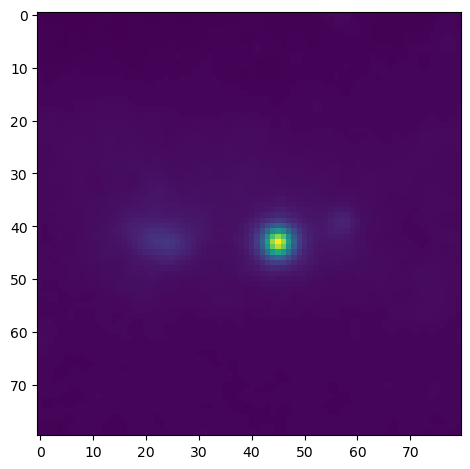

In [21]:
bkg_moview = unvec.transform(Xb)
im = plt.imshow(bkg_moview.mean(axis=0))
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/background_image_{fig_label}.png')

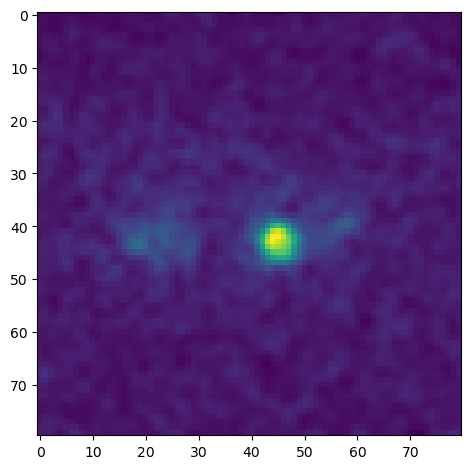

In [22]:
Xs = X - Xb
src_moview = unvec.transform(Xs)
im = plt.imshow(src_moview.mean(axis=0))
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_image_{fig_label}.png')

In [23]:
P = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pb = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pn = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    for col in range(0,n_time_steps-n_lags*lag_time):
        P[lag,:,col] = X[:,col+lag*lag_time]
        Pb[lag,:,col] = Xb[:,col+lag*lag_time]
        Pn[lag,:,col] = Xn[:,col+lag*lag_time]
print (f"P.shape = {P.shape}")

P.shape = (1, 6400, 120)


In [24]:
Pc = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pbf = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
for lag in range(0,n_lags+1):
    Pc[lag,:,:] = centered_matrix(P[lag,:,:])
    Pbf[lag,:,:] = P[lag,:,:] - Pb[lag,:,:]

X.shape = (6400, 120)
X_mean.shape = (6400, 120)


In [25]:
Z0 = []
for lag in range(0,n_lags+1):
    Z0 += [P[lag]]

Zn0 = []
for lag in range(0,n_lags+1):
    Zn0 += [Pn[lag]]

Z0 = np.concatenate(Z0, axis=0)
Zn0 = np.concatenate(Zn0, axis=0)
print (f"Z0.shape = {Z0.shape}")

Z0.shape = (6400, 120)


In [26]:
if analysis_type==0:
    Z0Z0T = covariance_matrix(Z0)
    Zn0Zn0T = covariance_matrix(Zn0)
else:
    Z0Z0T = similarity_matrix(Z0)
    Zn0Zn0T = similarity_matrix(Zn0)

S_Z0Z0T, U_Z0Z0T = eigen_decomposition(Z0Z0T)
S_Zn0Zn0T, U_Zn0Zn0T = eigen_decomposition(Zn0Zn0T)

eigenvectors.shape = (6400, 6400)
eigenvectors.shape = (6400, 6400)


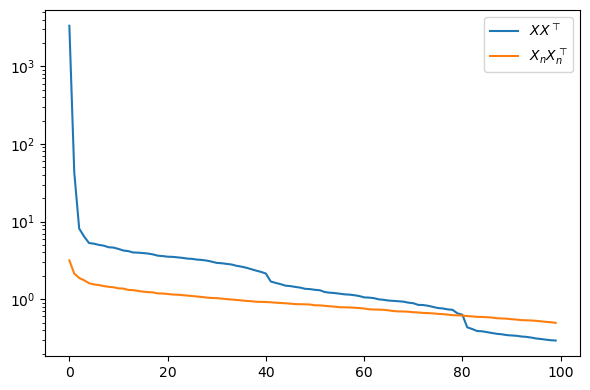

In [27]:
scaling = np.sum((S_Z0Z0T[50:]) / np.sum(S_Zn0Zn0T[50:]))

plot_rank = 100
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(S_Z0Z0T[:plot_rank], label="$XX^{\\top}$")
ax.plot(scaling*S_Zn0Zn0T[:plot_rank], label="$X_{n}X_{n}^{\\top}$")
ax.legend()
ax.set_yscale('log')
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/XXT_spectrum_{fig_label}.png')
plt.show()

In [28]:
nonzero_S = np.array([num for num in S_Z0Z0T if num > np.max(S_Z0Z0T)*1e-6])
nonzero_Sn = np.array([num for num in S_Zn0Zn0T if num > np.max(S_Zn0Zn0T)*1e-6])

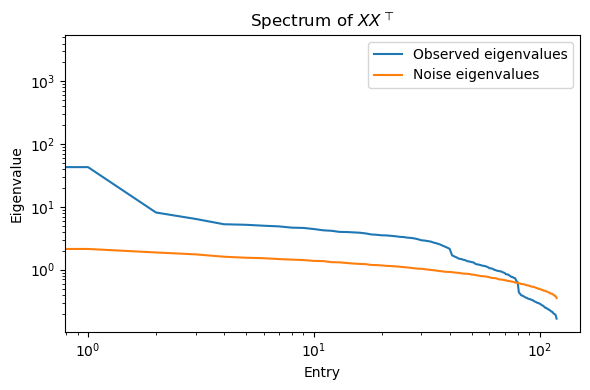

In [29]:
# --- Plot eigenvalue ---
descending_eigvals = np.sort(nonzero_S)[::-1]
descending_noise_eigvals = np.sort(nonzero_Sn)[::-1]

plt.figure(figsize=(6, 4))
plt.plot(descending_eigvals, label="Observed eigenvalues")
plt.plot(scaling * descending_noise_eigvals, label="Noise eigenvalues")
plt.legend()
plt.title("Spectrum of $XX^{\\top}$")
plt.xlabel("Entry")
plt.ylabel("Eigenvalue")
plt.yscale('log')
plt.xscale('log')
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/XXT_spectrum_{fig_label}.png')
plt.show()

largest noise eigenvalue: 3.167208728281562
lambda_max_bulk_fit = 3.167208728281562


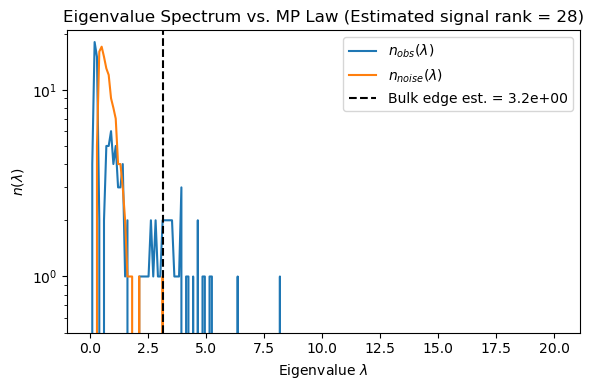

In [30]:
lambda_max_bulk = np.percentile(nonzero_S, 95)  # crude bulk upper estimate
n_bins = 50
x_min_fit = 0.0*lambda_max_bulk
x_max_fit = 1.0*lambda_max_bulk

hist_eigvals, bin_edges = np.histogram(nonzero_S, bins=n_bins, range=(x_min_fit, x_max_fit), density=False)
hist_err_eigvals = np.sqrt(hist_eigvals)
hist_err_eigvals[hist_err_eigvals == 0] = 1 # Set entries equal to 0 to 1

hist_noise_eigvals, bin_edges = np.histogram(scaling * nonzero_Sn, bins=n_bins, range=(x_min_fit, x_max_fit), density=False)

bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

extension_factor = 4.0
n_bins_plt = int(extension_factor*n_bins)
x_min_plt = x_min_fit
x_max_plt = extension_factor * x_max_fit
lam_vals_plt = np.linspace(x_min_plt, x_max_plt, n_bins_plt)

hist_eigvals_plt, bin_edges_plt = np.histogram(nonzero_S, bins=n_bins_plt, range=(x_min_plt, x_max_plt), density=False)
hist_noise_eigvals_plt, bin_edges_plt = np.histogram(scaling * nonzero_Sn, bins=n_bins_plt, range=(x_min_plt, x_max_plt), density=False)

print (f"largest noise eigenvalue: {scaling * descending_noise_eigvals[0]}")

lambda_max_bulk_fit = scaling * (descending_noise_eigvals[0])
# percentile = 1.0/float(len(nonzero_Sn)) * 100.
# lambda_max_bulk_fit = np.percentile(scaling * nonzero_Sn, 100-percentile)
# lambda_max_bulk_fit += scaling * (descending_noise_eigvals[1] - descending_noise_eigvals[2])

print (f"lambda_max_bulk_fit = {lambda_max_bulk_fit}")
estimate_rank_signal = np.sum(nonzero_S > lambda_max_bulk_fit)

plt.figure(figsize=(6, 4))
plt.plot(lam_vals_plt, hist_eigvals_plt, label="$n_{obs}(\lambda)$")
plt.plot(lam_vals_plt, hist_noise_eigvals_plt, label="$n_{noise}(\lambda)$")
plt.axvline(lambda_max_bulk_fit, color='k', linestyle='--', label=f"Bulk edge est. = {lambda_max_bulk_fit:0.1e}")
plt.title(f"Eigenvalue Spectrum vs. MP Law (Estimated signal rank = {estimate_rank_signal})")
plt.xlabel("Eigenvalue $\lambda$")
plt.ylabel("$n(\lambda)$")
plt.yscale('log')
# plt.xlim([0, 1.2*lambda_max_bulk_fit])
plt.ylim(bottom=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/MP_fit_{fig_label}.png')
plt.show()

In [31]:
k = estimate_rank_signal
if simulation:
    k = n_sources
print (f"k = {k}")

k = 28


In [32]:
Pw = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pcw = np.zeros((n_lags+1,n_pixels,n_time_steps-n_lags*lag_time))
Pw_eco = np.zeros((n_lags+1,k,n_time_steps-n_lags*lag_time))
Pw_eco_T = np.zeros((n_lags+1,n_pixels,k))
for lag in range(0,n_lags+1):
    if use_centering==3:
        Pw_eco[lag,:,:] = eco_whitened_matrix(Pbf[lag,:,:],Pc[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(Pbf[lag,:,:],Pc[lag,:,:],k)
        Pcw[lag,:,:] = whitened_matrix(Pbf[lag,:,:],Pc[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
    elif use_centering==2:
        Pw_eco[lag,:,:] = eco_whitened_matrix(Pc[lag,:,:],Pc[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(Pc[lag,:,:],Pc[lag,:,:],k)
        Pcw[lag,:,:] = whitened_matrix(Pc[lag,:,:],Pc[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
    elif use_centering==1:
        Pw_eco[lag,:,:] = eco_whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(P[lag,:,:],Pc[lag,:,:],k)
        Pcw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],Pc[lag,:,:],k)
    elif use_centering==0:
        Pw_eco[lag,:,:] = eco_whitened_matrix(P[lag,:,:],P[lag,:,:],k)
        Pw_eco_T[lag,:,:] = eco_whitened_matrix_T(P[lag,:,:],P[lag,:,:],k)
        Pcw[lag,:,:] = whitened_matrix(P[lag,:,:],P[lag,:,:],k)
        Pw[lag,:,:] = whitened_matrix(P[lag,:,:],P[lag,:,:],k)
print (f"P.shape = {P.shape}")
print (f"Pw.shape = {Pw.shape}")
print (f"Pw_eco.shape = {Pw_eco.shape}")
print (f"Pw_eco_T.shape = {Pw_eco_T.shape}")

X.shape = (6400, 120)
inv_S.shape = (28, 28)
inv_S_reshape.shape = (28, 6400)
W.shape = (28, 6400)
X.shape = (6400, 120)
inv_S.shape = (28, 28)
inv_S_reshape.shape = (120, 28)
VT.shape = (120, 120)
W.shape = (120, 28)
eigenvectors.shape = (6400, 6400)
eigenvectors.shape = (6400, 6400)
P.shape = (1, 6400, 120)
Pw.shape = (1, 6400, 120)
Pw_eco.shape = (1, 28, 120)
Pw_eco_T.shape = (1, 6400, 28)


In [ ]:
# verify that Pw is whitened data
COV = covariance_matrix(Pw[0,:,:])
sns.heatmap(COV[:, :])
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/whitened_PTP_{fig_label}.png')

In [ ]:
Z = []
Zc = []

if use_whitening:
    for lag in range(0,n_lags+1):
        Z += [Pw[lag]]
        Zc += [Pcw[lag]]
else:
    for lag in range(0,n_lags+1):
        Z += [P[lag]]
        Zc += [Pc[lag]]

Z = np.concatenate(Z, axis=0)
Zc = np.concatenate(Zc, axis=0)

In [ ]:
ZTZ = similarity_matrix(Zc)
ZZT = covariance_matrix(Zc)

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(ZTZ)
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/ZTZ_{fig_label}.png')
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(ZZT)
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/ZZT_{fig_label}.png')
plt.show()

In [ ]:
from sklearn.utils.extmath import randomized_svd
def nnsvd(X_init, k, eps: float = 1e-6):
    U, S, V = randomized_svd(X_init, n_components=k)
    W = np.zeros_like(U)
    H = np.zeros_like(V)
    
    # The leading singular triplet is non-negative
    # so it can be used as is for initialization.
    W[:, 0] = np.sqrt(S[0]) * np.abs(U[:, 0])
    H[0, :] = np.sqrt(S[0]) * np.abs(V[0, :])
    
    for j in range(1, k):
        x, y = U[:, j], V[j, :]
    
        # extract positive and negative parts of column vectors
        x_p, y_p = np.maximum(x, 0), np.maximum(y, 0)
        x_n, y_n = np.abs(np.minimum(x, 0)), np.abs(np.minimum(y, 0))
    
        # and their norms
        x_p_nrm, y_p_nrm = np.linalg.norm(x_p, ord=2), np.linalg.norm(y_p, ord=2)
        x_n_nrm, y_n_nrm = np.linalg.norm(x_n, ord=2), np.linalg.norm(y_n, ord=2)
    
        m_p, m_n = x_p_nrm * y_p_nrm, x_n_nrm * y_n_nrm
    
        # choose update
        if m_p > m_n:
            u = x_p / x_p_nrm
            v = y_p / y_p_nrm
            sigma = m_p
        else:
            u = x_n / x_n_nrm
            v = y_n / y_n_nrm
            sigma = m_n
    
        lbd = np.sqrt(S[j] * sigma)
        W[:, j] = lbd * u
        H[j, :] = lbd * v
    
    W[W < eps] = 0
    H[H < eps] = 0
    
    return W, H


In [ ]:
H_init = 2 * np.random.rand(ZTZ.shape[0], k).T
W_init = 2 * np.random.rand(ZZT.shape[0], k)

print (f"H_init.shape = {H_init.shape}")
print (f"W_init.shape = {W_init.shape}")

if use_eco_init:

    W_init, H_init = nnsvd(Z,k)
    
    # H_init = np.zeros((n_time_steps-n_lags*lag_time,k)).T
    # W_init = np.zeros(((n_lags+1)*n_pixels,k))
    # for lag in range(0,n_lags+1):
    #     H_init += np.abs(Pw_eco[lag,:,:])
    #     W_init[lag*n_pixels:(lag+1)*n_pixels,:] += np.abs(Pw_eco_T[lag,:,:])

HTH_init = similarity_matrix(H_init)
print (HTH_init)

fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
ax.imshow(np.abs(HTH_init))
plt.tight_layout()
plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/HTH_init_{fig_label}.png')
plt.show()

In [ ]:
from tqdm.notebook import tqdm

eta = 0.1
error_stop = 1e-4
n_iterations = 5000
error_log = np.zeros(n_iterations)

H = H_init
H = H.clip(0)
W = W_init
W = W.clip(0)

N = Z.shape[0]
T = Z.shape[1]

ones = np.ones((T,1))
RH = np.zeros((k,N))
CH = np.zeros((k,1))
tilde_Z = np.vstack((Zc,ones.T))
inv_tilde_Z = np.linalg.pinv(tilde_Z, rcond=1e-15)

epsilon = 1e-10
epsilon_mtx = np.ones_like(H@H.T@H) * epsilon

beta = 1.0

if analysis_type==0:
    
    for n_iter in tqdm(range(n_iterations)):
        H_old = H.copy()
    
        # gamma = H_old @ ZTZ / (beta * (H_old @ H_old.T @ H_old / float(T)) + epsilon_mtx)
        # H = H_old * (1-eta) + eta * H_old * gamma

        H = H_old + eta * (H_old @ ZTZ - beta * H_old @ H_old.T @ H_old / float(T))
        H = H.clip(0)  
        
        er = np.divide(np.abs(H - H_old), np.abs(H_old + epsilon)).mean() / eta
        error_log[n_iter] = er
        # print (f"er = {er}")
    
        if er < error_stop:
            break

    if fit_bias:
        for n_iter in tqdm(range(n_iterations)):
            H_old = H.copy()

            H = H_old + eta * (H_old @ ZTZ - beta * H_old @ H_old.T @ H_old / float(T))
            tilde_RH = H @ inv_tilde_Z

            RH[:,:] = tilde_RH[:,:-1]
            CH[:,:] = -tilde_RH[:,-1:]
            RHZc = RH @ Zc / float(N)
            RHZc = RHZc.clip(0)
            CH = CH.clip(0)
            RH = RHZc @ Zc.T / float(T)
            tilde_RH[:,:-1] = RH[:,:]
            tilde_RH[:,-1:] = -CH[:,:]
            
            H = tilde_RH @ tilde_Z / float(N)

            er = np.divide(np.abs(H - H_old), np.abs(H_old + epsilon)).mean() / eta
            error_log[n_iter] = er
            # print (f"er = {er}")
        
            if er < error_stop:
                break

elif analysis_type==1:
    
    for n_iter in tqdm(range(n_iterations)):
        W_old = W.copy() 
    
        W = W_old + eta * (ZZT @ W_old - beta * W_old @ W_old.T @ W_old / float(N))
        W = W.clip(0)
        
        er = np.divide(np.abs(W - W_old), np.abs(W_old + epsilon)).mean() / eta
        error_log[n_iter] = er
        # print (f"er = {er}")
    
        if er < error_stop:
            break

In [ ]:
plt.plot(error_log)
plt.yscale('log')
# plt.xscale('log')
plt.show()

In [ ]:
if analysis_type==0:
    HTH = similarity_matrix(H)
    print (HTH)
    
    fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
    ax.imshow(np.abs(HTH))
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/HTH_{fig_label}.png')
    plt.show()
else:
    WWT = covariance_matrix(W)
    print (WWT)
    
    fig, ax = plt.subplots(1, 1, figsize=(6.4, 6.4))
    ax.imshow(np.abs(WWT[:n_pixels,n_lags*n_pixels:]))
    plt.tight_layout()
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/WWT_{fig_label}.png')
    plt.show()

In [ ]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics.pairwise import cosine_similarity

def permute_rows_to_maximize_trace(A):
    """
    Permute the rows of a square matrix A to maximize the trace of the resulting matrix.
    
    Parameters:
        A (numpy.ndarray): Square matrix of shape (n, n)
        
    Returns:
        A_permuted (numpy.ndarray): Matrix with permuted rows
        permutation (numpy.ndarray): The optimal row permutation
        max_trace (float): The maximum trace achieved
    """
    # Convert maximization to minimization by negating the matrix
    cost_matrix = -A
    row_indices, col_indices = linear_sum_assignment(cost_matrix)

    # Apply the optimal row permutation
    A_permuted = A[:, col_indices]
    max_trace = np.trace(A_permuted)
    
    return A_permuted, row_indices, col_indices, max_trace

def sort_solutions(H, H_ref):

    M_cossim = cosine_similarity(H, H_ref)
    print (f"M_cossim.shape = {M_cossim.shape}")
    M_cossim_permute, row_indices, col_indices, _ = permute_rows_to_maximize_trace(M_cossim)
    print (f"row_indices = {row_indices}")
    print (f"col_indices = {col_indices}")

    H_sorted = H[col_indices, :]
    
    return H_sorted

In [ ]:
if analysis_type==0:
    H = sort_solutions(H, H_init)
else:
    WT = sort_solutions(W.T, W_init.T)
    W = WT.T

In [ ]:
# Zs = Z0
# Zs = Z
Zs = Zc
if analysis_type==0:

    if not fit_bias:
        A_concatenated = Zc @ H.T
        S_solved_by_sim = A_concatenated.T @ Zs
        # S_solved_by_sim = H
    else:
        S_solved_by_sim = RH @ Zs
        A_concatenated = RH.T
    print (f"A_concatenated.shape = {A_concatenated.shape}")
    
    A_solved_by_sim = np.zeros((n_pixels,k))
    if n_lags==0:
        A_solved_by_sim += A_concatenated
    else:
        for lag in range(0,n_lags+1):
            A_solved_by_sim[:,:] += A_concatenated[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
    
    S_solved_by_sim = S_solved_by_sim.clip(0)
    A_solved_by_sim = A_solved_by_sim.clip(0)
    
    image_array_by_sim = []
    for entry in range(0,k):
        snapshot = unvec.transform(A_solved_by_sim[:,entry])
        image_array_by_sim += [snapshot]

else:

    A_solved_by_cov = np.zeros((n_pixels,k))
    if n_lags==0:
        A_solved_by_cov += W
    else:
        for lag in range(0,n_lags+1):
            A_solved_by_cov[:,:] += W[lag*n_pixels:(lag+1)*n_pixels,:] / float(n_lags+1)
    S_solved_by_cov = W.T @ Zs
    
    S_solved_by_cov = S_solved_by_cov.clip(0)
    A_solved_by_cov = A_solved_by_cov.clip(0)
    
    image_array_by_cov = []
    for entry in range(0,k):
        snapshot = unvec.transform(A_solved_by_cov[:,entry])
        image_array_by_cov += [snapshot]
        

In [ ]:
if simulation:

    truth_vec = vectorizer.fit_transform(source_footprints).T
    # truth_vec = traces_filtercentered
    print (f"truth_vec.shape = {truth_vec.shape}")

    if analysis_type==0:
        cluster_matching_by_sim = []
        selected_cluster_by_sim = []
        for src in range(0,n_sources):
            max_corr = 0.
            pair_indices = [src,src]
            for cluster in range(0,k):
                if cluster in selected_cluster_by_sim: 
                    continue
                corr = truth_vec[src] @ A_solved_by_sim[:,cluster].T / np.sqrt(1e-5 + A_solved_by_sim[:,cluster] @ A_solved_by_sim[:,cluster].T * truth_vec[src] @ truth_vec[src].T)
                # corr = truth_vec[src].T @ S_solved_by_sim[cluster,:] / np.sqrt(1e-5 + S_solved_by_sim[cluster,:].T @ S_solved_by_sim[cluster,:] * truth_vec[src].T @ truth_vec[src])
                if corr >= max_corr:
                    max_corr = corr
                    pair_indices = [src, cluster]
            cluster_matching_by_sim += [pair_indices]
            selected_cluster_by_sim += [pair_indices[1]]
        print (f"cluster_matching = {cluster_matching_by_sim}")

    if analysis_type==1:
        cluster_matching_by_cov = []
        selected_cluster_by_cov = []
        for src in range(0,n_sources):
            max_corr = 0.
            pair_indices = []
            for cluster in range(0,k):
                if cluster in selected_cluster_by_cov: 
                    continue
                corr = truth_vec[src] @ A_solved_by_cov[:,cluster].T / np.sqrt(1e-5 + A_solved_by_cov[:,cluster] @ A_solved_by_cov[:,cluster].T * truth_vec[src] @ truth_vec[src].T)
                # corr = truth_vec[src].T @ S_solved_by_cov[cluster,:] / np.sqrt(1e-5 + S_solved_by_cov[cluster,:].T @ S_solved_by_cov[cluster,:] * truth_vec[src].T @ truth_vec[src])
                if corr >= max_corr:
                    max_corr = corr
                    pair_indices = [src, cluster]
            cluster_matching_by_cov += [pair_indices]
            selected_cluster_by_cov += [pair_indices[1]]
        print (f"cluster_matching = {cluster_matching_by_cov}")


In [ ]:
if analysis_type==0:

    matching_score = 0.
    truth_score = 0.
    if simulation:
        reco_levels = [0.60]
        for src in range(0,n_sources):
            truth_levels = [0.60]
            fig, ax = plt.subplots(2, 2, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 3]})
            cluster = cluster_matching_by_sim[src][1]
            reco_levels = [0.30*np.max(image_array_by_sim[cluster])]
            ax[0][0].imshow(movie.mean(axis=0))
            ax[0][0].contour(source_footprints[src], levels=truth_levels, colors='r')
            # ax[0][0].contour(image_array_by_sim[cluster] / np.max(image_array_by_sim[cluster]), levels=reco_levels, colors='w')
            ax[1][0].imshow(image_array_by_sim[cluster])
            ax[1][1].plot(S_solved_by_sim[cluster], label="reconstruction")
            ax[0][1].plot(traces[src], label="truth", color="orange")
            # ax[2].legend()
            plt.tight_layout()
            plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_sim_{fig_label}.png')
            plt.show()
    
            matching_score += S_solved_by_sim[cluster].T @ traces[src,n_lags*lag_time:]
            truth_score += np.sqrt(traces[src,n_lags*lag_time:].T @ traces[src,n_lags*lag_time:] * S_solved_by_sim[cluster].T @ S_solved_by_sim[cluster])
    
        print (f"matching_score / truth_score = {matching_score / truth_score}")
    else:
        for src in range(0,k):
            reco_levels = [0.30*np.max(image_array_by_sim[src])]
            fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
            ax[0].imshow(movie.mean(axis=0))
            ax[0].contour(image_array_by_sim[src], levels=reco_levels, colors='w')
            ax[1].imshow(image_array_by_sim[src], cmap="Reds")
            ax[2].plot(S_solved_by_sim[src])
            plt.tight_layout()
            plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_sim_{fig_label}.png')
            plt.show()

else:

    matching_score = 0.
    truth_score = 0.
    if simulation:
        reco_levels = [0.60]
        for src in range(0,n_sources):
            truth_levels = [0.60]
            reco_levels = [0.60*np.max(image_array_by_cov[cluster])]
            fig, ax = plt.subplots(2, 2, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 3]})
            cluster = cluster_matching_by_cov[src][1]
            ax[0][0].imshow(movie.mean(axis=0))
            ax[0][0].contour(source_footprints[src], levels=truth_levels, colors='r')
            # ax[0][0].contour(image_array_by_cov[cluster] / np.max(image_array_by_cov[cluster]), levels=reco_levels, colors='w')
            ax[1][0].imshow(image_array_by_cov[cluster])
            ax[1][1].plot(S_solved_by_cov[cluster], label="reconstruction")
            ax[0][1].plot(traces[src], label="truth", color="orange")
            # ax[2].legend()
            plt.tight_layout()
            plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_cov_{fig_label}.png')
            plt.show()
    
            matching_score += S_solved_by_cov[cluster].T @ traces[src,n_lags*lag_time:]
            truth_score += np.sqrt(traces[src,n_lags*lag_time:].T @ traces[src,n_lags*lag_time:] * S_solved_by_cov[cluster].T @ S_solved_by_cov[cluster])
    
        print (f"matching_score / truth_score = {matching_score / truth_score}")
    else:
        for src in range(0,k):
            reco_levels = [0.50*np.max(image_array_by_cov[src])]
            fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
            ax[0].imshow(movie.mean(axis=0))
            ax[0].contour(image_array_by_cov[src], levels=reco_levels, colors='w')
            ax[1].imshow(image_array_by_cov[src], cmap="Reds")
            ax[2].plot(S_solved_by_cov[src])
            plt.tight_layout()
            plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_extract_src{src}_by_cov_{fig_label}.png')
            plt.show()

In [ ]:
n_row = int(np.sqrt(k))
n_col = int(k/n_row)
if k>n_row*n_col:
    n_row += 1
if n_row==1:
    n_row += 1
if n_col==1:
    n_col += 1
fig, ax = plt.subplots(n_row, n_col, figsize=(n_col * 4.8, n_row * 4.8))
entry = 0
for row in range(0,n_row):
    for col in range(0,n_col):
        if entry>=k: continue
        if analysis_type==0:
            ax[row][col].imshow(image_array_by_sim[entry])
        else:
            ax[row][col].imshow(image_array_by_cov[entry])
        entry += 1
plt.tight_layout()
if analysis_type==0:
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_footprint_by_sim_{fig_label}.png')
else:
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/source_footprint_by_cov_{fig_label}.png')
plt.show()

In [ ]:
if not simulation:
    if "pkl" in path:
        n_time_frames_per_window = int(n_time_steps/n_energy_bins)
        if analysis_type==0:
            reco_levels = [0.50*np.max(image_array_by_sim[src])]
            for src in range(0,k):
                fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
                for tw in range(0,n_energy_bins):
                    ax[0].imshow(movie.mean(axis=0))
                    ax[0].contour(image_array_by_sim[src], levels=reco_levels, colors='w')
                    ax[1].imshow(image_array_by_sim[src], cmap="Reds")
                    S = S_solved_by_sim[src][tw*n_time_frames_per_window:(tw+1)*n_time_frames_per_window]
                    S_norm = np.sum(S)
                    ax[2].plot(S, drawstyle='steps', alpha=0.5)
                plt.tight_layout()
                plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/energy_lightcurve_src{src}_by_sim_{fig_label}.png')
                plt.show()
        elif analysis_type==1:
            reco_levels = [0.50*np.max(image_array_by_cov[src])]
            for src in range(0,k):
                fig, ax = plt.subplots(1, 3, figsize=(10, 2), gridspec_kw={'width_ratios': [1, 1, 3]})
                for tw in range(0,n_energy_bins):
                    ax[0].imshow(movie.mean(axis=0))
                    ax[0].contour(image_array_by_cov[src], levels=reco_levels, colors='w')
                    ax[1].imshow(image_array_by_cov[src], cmap="Reds")
                    S = S_solved_by_cov[src][tw*n_time_frames_per_window:(tw+1)*n_time_frames_per_window]
                    S_norm = np.sum(S)
                    ax[2].plot(S, drawstyle='steps', alpha=0.5)
                plt.tight_layout()
                plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/energy_lightcurve_src{src}_by_cov_{fig_label}.png')
                plt.show()

In [ ]:
if simulation:
    if analysis_type==0:
        M_cossim = cosine_similarity(S_solved_by_sim, traces[:,:n_time_steps-n_lags*lag_time])
        M_cossim_permute, _, _, max_trace = permute_rows_to_maximize_trace(M_cossim)
        print (f"max_trace = {max_trace/M_cossim.shape[0]}")
        
        fig, ax = plt.subplots(1, 1, figsize=(6, 6))
        im = ax.imshow(M_cossim_permute)
        cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.8)
        plt.title(f"Average cosine similarity {max_trace/M_cossim.shape[0]:0.2f}")
        plt.tight_layout()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_cos_similarity_by_sim_{fig_label}.png')
        plt.show()

In [ ]:
if simulation:
    if analysis_type==1:
        M_cossim = cosine_similarity(S_solved_by_cov, traces[:,:n_time_steps-n_lags*lag_time])
        M_cossim_permute, _, _, max_trace = permute_rows_to_maximize_trace(M_cossim)
        print (f"max_trace = {max_trace/M_cossim.shape[0]}")

        fig, ax = plt.subplots(1, 1, figsize=(6, 6))
        im = ax.imshow(M_cossim_permute)
        cbar = fig.colorbar(im, location='right', anchor=(0, 0.5), shrink=0.8)
        plt.title(f"Average cosine similarity {max_trace/M_cossim.shape[0]:0.2f}")
        plt.tight_layout()
        plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/truth_cos_similarity_by_cov_{fig_label}.png')
        plt.show()
        

In [ ]:
if analysis_type==0:
    M_cossim = cosine_similarity(A_solved_by_sim.T, A_solved_by_sim.T)
    M_cossim_dim = M_cossim.shape[0]
    M_cossim_trace = np.trace(M_cossim)
    M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
    print (f"M_cossim_meanoff = {M_cossim_meanoff}")
    sns.heatmap(M_cossim)
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/A_cos_similarity_by_sim_{fig_label}.png')

In [ ]:
if analysis_type==1:
    M_cossim = cosine_similarity(A_solved_by_cov.T, A_solved_by_cov.T)
    M_cossim_dim = M_cossim.shape[0]
    M_cossim_trace = np.trace(M_cossim)
    M_cossim_meanoff = (np.sum(M_cossim) - M_cossim_trace)/(M_cossim_dim*M_cossim_dim-M_cossim_dim)
    print (f"M_cossim_meanoff = {M_cossim_meanoff}")
    sns.heatmap(M_cossim)
    plt.savefig(f'/Users/rshang/Work/caiman/mesmerize-core/notebooks/outputs/A_cos_similarity_by_cov_{fig_label}.png')